<a href="https://colab.research.google.com/github/kejal2005/ATM-SIMULATOR/blob/main/Problem_21_(Bio_Inspired).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Team 21:Customer Segmentation
##Group synthetic customer records based on purchase frequency, spending, and product preferences using an unsupervised clustering algorithm

##Kejal Jain (RA2311003010127)
##Harsh Jain (RA2311003011135)

#**Data**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

print("Problem 21: Customer Segmentation")
print("Team: Kejal Jain (RA2311003010127), Harsh Jain (RA2311003011135)")

np.random.seed(42)
categories = ["Electronics", "Fashion", "Grocery", "Home"]
groups = [
    (600, 40, 3500, [8, 2, 1, 3]),
    (900, 45, 600, [1, 1, 10, 3]),
    (700, 20, 1800, [1, 10, 1, 1]),
    (800, 6, 1500, [2, 2, 2, 2]),
]

parts = []
for n, freq_mean, order_value, alpha in groups:
    freq = np.maximum(1, np.random.poisson(freq_mean, n))
    value = np.random.lognormal(np.log(order_value), 0.25, n)
    part = pd.DataFrame(np.random.dirichlet(alpha, n), columns=categories)
    part.insert(0, "total_spend", (freq * value).round(2))
    part.insert(0, "purchase_frequency", freq)
    parts.append(part)

df = pd.concat(parts, ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)
df[categories] = df[categories].round(3)

print("Shape:", df.shape)
df.head(10)

Problem 21: Customer Segmentation
Team: Kejal Jain (RA2311003010127), Harsh Jain (RA2311003011135)
Shape: (3000, 6)


,purchase_frequency,total_spend,Electronics,Fashion,Grocery,Home
0,13,29019.37,0.040,0.882,0.052,0.026
1,61,29798.69,0.006,0.012,0.673,0.309
2,21,23438.94,0.021,0.870,0.009,0.100
3,37,107267.57,0.417,0.304,0.016,0.264
4,8,11811.88,0.396,0.266,0.240,0.099
5,36,32027.49,0.009,0.033,0.619,0.340
6,46,44666.43,0.017,0.152,0.741,0.090
7,25,43563.29,0.022,0.759,0.131,0.089
8,44,119983.74,0.615,0.311,0.006,0.068
9,4,6442.22,0.157,0.375,0.161,0.307


#**Data overview**

Missing values: 0


,purchase_frequency,total_spend,Electronics,Fashion,Grocery,Home
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,27.66,48561.77,0.22,0.29,0.30,0.19
std,16.87,54086.37,0.22,0.29,0.27,0.12
min,1.00,987.81,0.00,0.00,0.00,0.00
25%,10.00,15089.03,0.04,0.07,0.06,0.09
50%,28.00,28481.96,0.12,0.17,0.18,0.17
75%,43.00,48298.94,0.37,0.48,0.56,0.26
max,71.00,326591.28,0.90,0.99,0.95,0.73


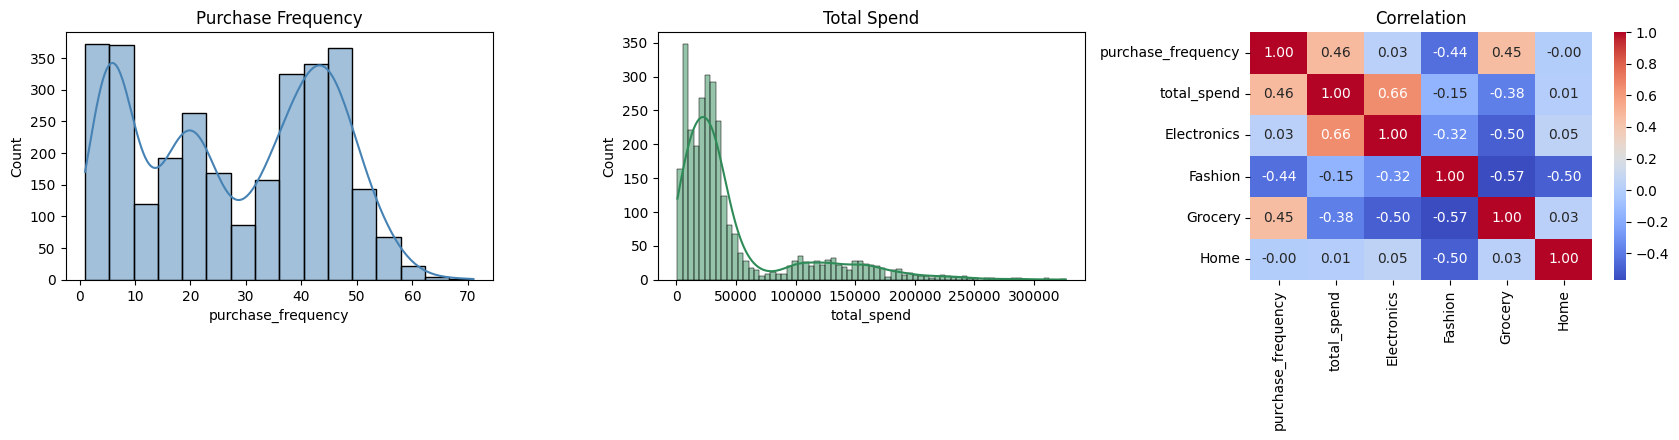

In [ ]:
print("Missing values:", df.isnull().sum().sum())
display(df.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df["purchase_frequency"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Purchase Frequency")
sns.histplot(df["total_spend"], kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("Total Spend")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[2])
axes[2].set_title("Correlation")
plt.tight_layout()
plt.show()

# **Scaling and choosing the number of clusters**

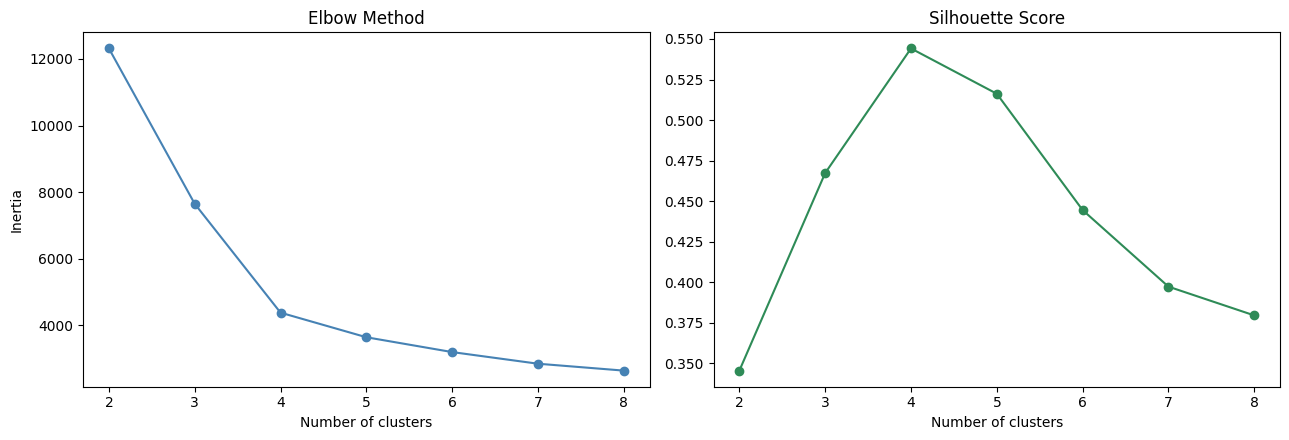

Best number of clusters: 4


In [ ]:
X = df[["purchase_frequency", "total_spend"] + categories].copy()
X["total_spend"] = np.log1p(X["total_spend"])
Xs = StandardScaler().fit_transform(X)

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xs)
    inertia.append(model.inertia_)
    sil.append(silhouette_score(Xs, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inertia, "o-", color="steelblue")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[1].plot(ks, sil, "o-", color="seagreen")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters")
plt.tight_layout()
plt.show()

best_k = list(ks)[int(np.argmax(sil))]
print("Best number of clusters:", best_k)

# **K-Means clustering and visualization**



Silhouette Score: 0.544
cluster
0    901
1    779
2    600
3    720
Name: count, dtype: int64


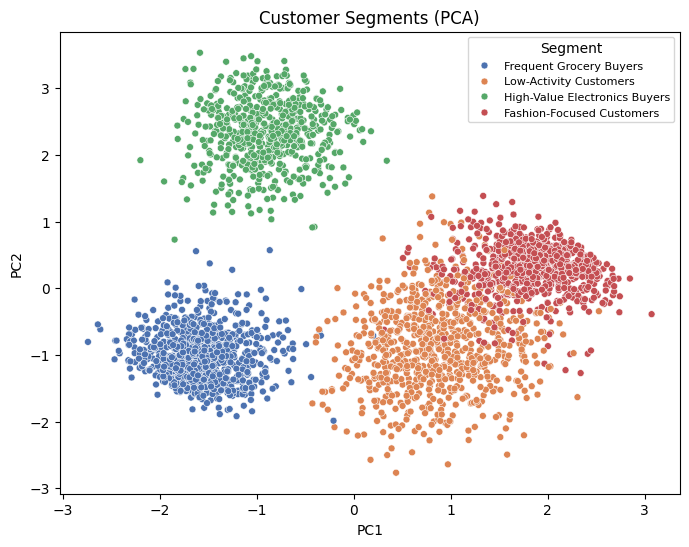

In [ ]:
kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=42)
df["cluster"] = kmeans.fit_predict(Xs)

segment_names = {
    0: "Frequent Grocery Buyers",
    1: "Low-Activity Customers",
    2: "High-Value Electronics Buyers",
    3: "Fashion-Focused Customers",
}
df["segment"] = df["cluster"].map(segment_names)

print("Silhouette Score:", round(silhouette_score(Xs, df["cluster"]), 3))
print(df["cluster"].value_counts().sort_index())

pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(Xs)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=df["segment"],
                hue_order=list(segment_names.values()), palette="deep", s=25)
plt.title("Customer Segments (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Segment", fontsize=8)
plt.show()

#**Segment Profiles**

,purchase_frequency,total_spend,Electronics,Fashion,Grocery,Home,customers,revenue_share_%
segment,,,,,,,,
Frequent Grocery Buyers,44.87,27629.71,0.06,0.07,0.67,0.20,901,17.1
Low-Activity Customers,5.98,9304.47,0.26,0.25,0.24,0.25,779,5.0
High-Value Electronics Buyers,39.67,145547.73,0.58,0.14,0.07,0.21,600,59.9
Fashion-Focused Customers,19.55,36408.50,0.08,0.76,0.08,0.08,720,18.0


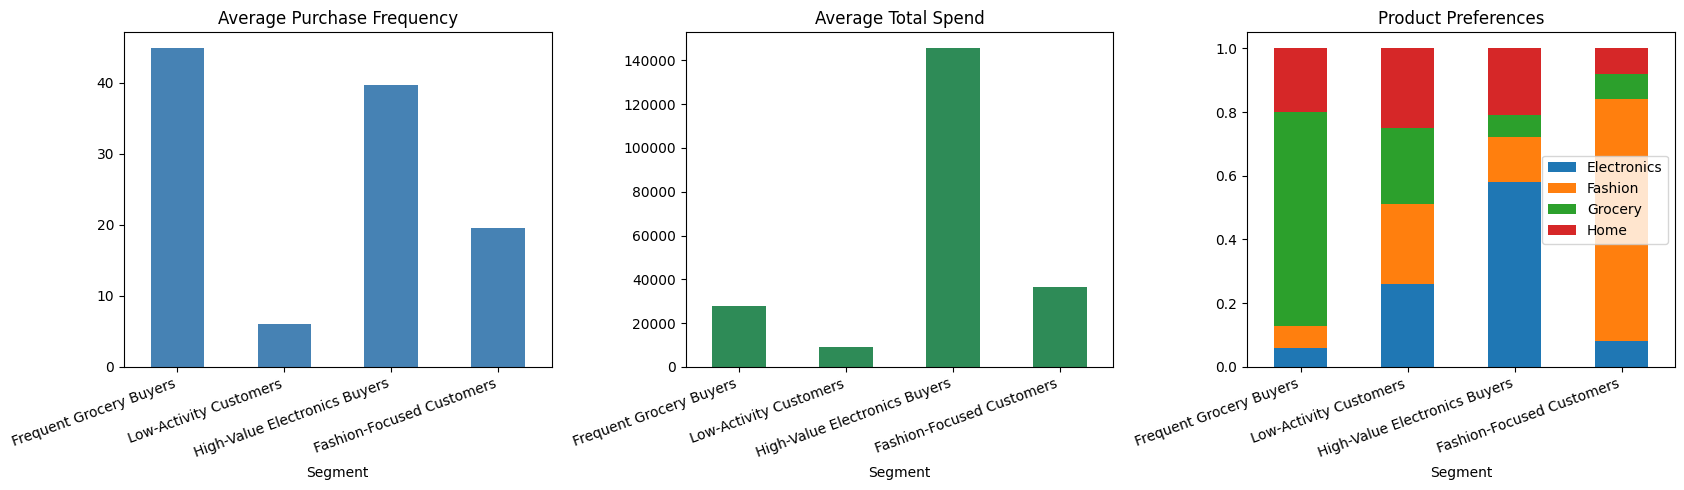

In [ ]:
profile = df.groupby("cluster").mean(numeric_only=True).round(2)
profile["customers"] = df["cluster"].value_counts().sort_index()
profile["revenue_share_%"] = (
    df.groupby("cluster")["total_spend"].sum()
    / df["total_spend"].sum() * 100
).round(1)

profile.index = profile.index.map(segment_names)
profile.index.name = "segment"
display(profile)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
profile["purchase_frequency"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Average Purchase Frequency")
profile["total_spend"].plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Average Total Spend")
profile[categories].plot(kind="bar", stacked=True, ax=axes[2])
axes[2].set_title("Product Preferences")
for ax in axes:
    ax.set_xlabel("Segment")
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()